In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('agaricus-lepiota.data')
df.head()

,poisonous,cap-shape,cap-surface,cap-color,bruises?,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
# x = np.arrange(2)

p_df = df[df['poisonous'] == 'p']
np_df = df[df['poisonous'] == 'e']

In [4]:
p_df

,poisonous,cap-shape,cap-surface,cap-color,bruises?,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
8,p,x,y,w,t,p,f,c,n,p,...,s,w,w,p,w,o,p,k,v,g
13,p,x,y,w,t,p,f,c,n,k,...,s,w,w,p,w,o,p,n,v,u
17,p,x,s,n,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8114,p,f,y,c,f,m,a,c,b,y,...,y,c,c,p,w,n,n,w,c,d
8116,p,k,y,n,f,s,f,c,n,b,...,k,p,w,p,w,o,e,w,v,l
8117,p,k,s,e,f,y,f,c,n,b,...,s,p,w,p,w,o,e,w,v,d
8118,p,k,y,n,f,f,f,c,n,b,...,s,p,w,p,w,o,e,w,v,d


In [5]:
np_df

,poisonous,cap-shape,cap-surface,cap-color,bruises?,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
5,e,x,y,y,t,a,f,c,b,n,...,s,w,w,p,w,o,p,k,n,g
6,e,b,s,w,t,a,f,c,b,g,...,s,w,w,p,w,o,p,k,n,m
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8115,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,o,v,l
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l


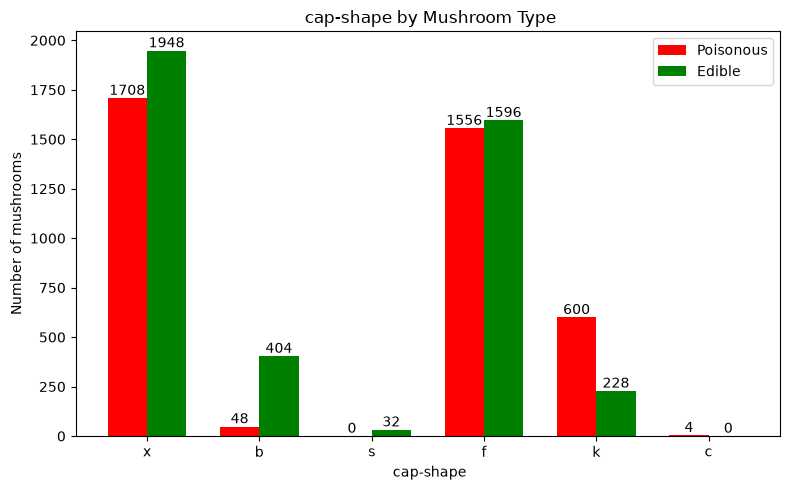

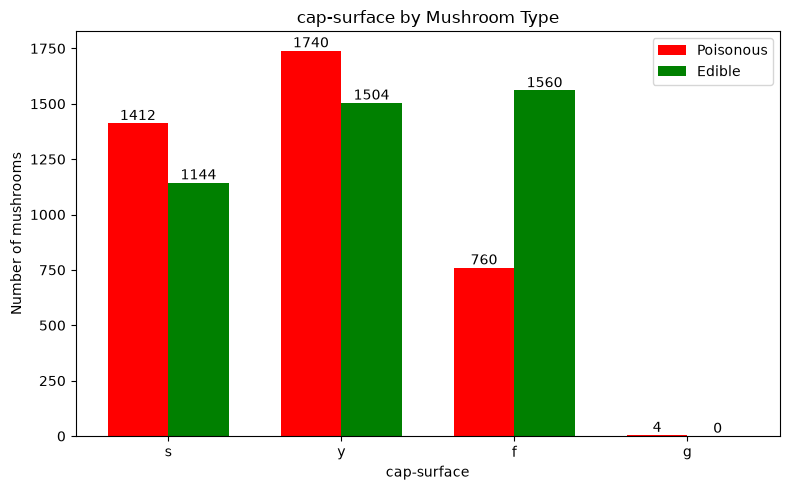

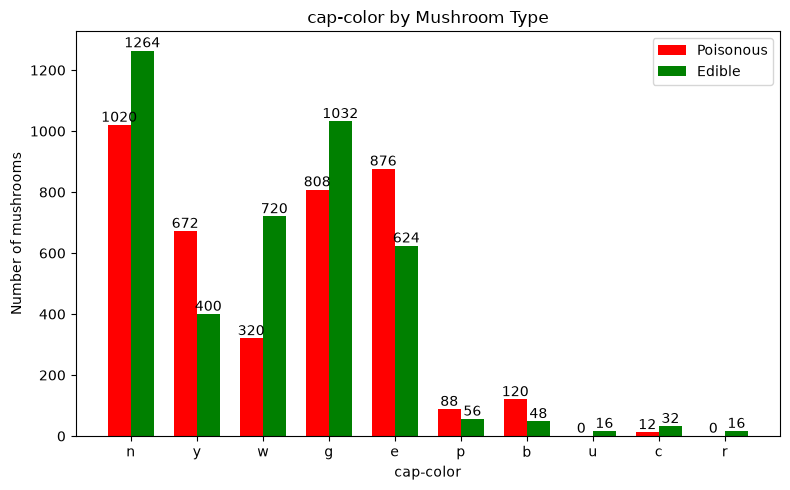

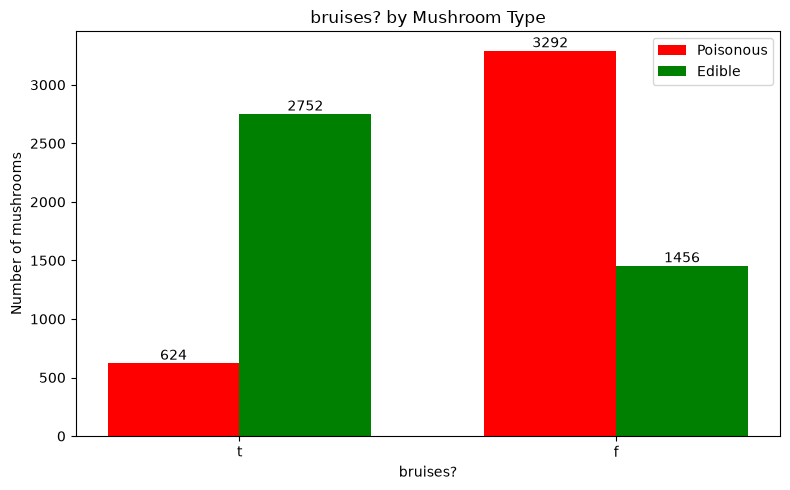

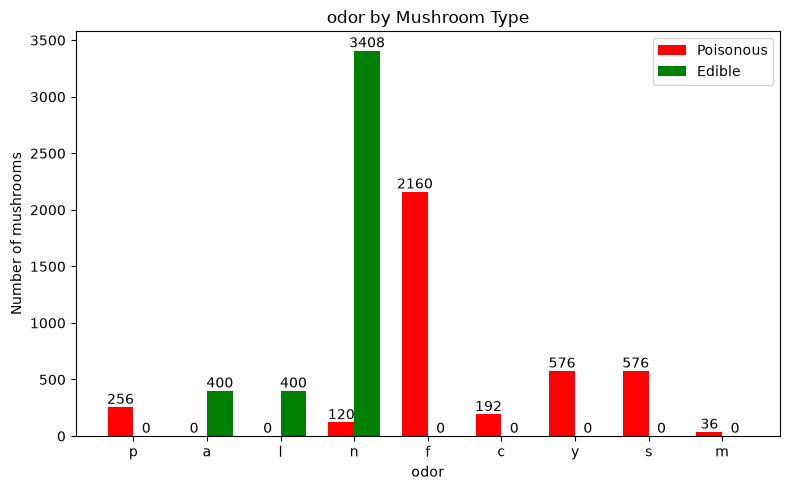

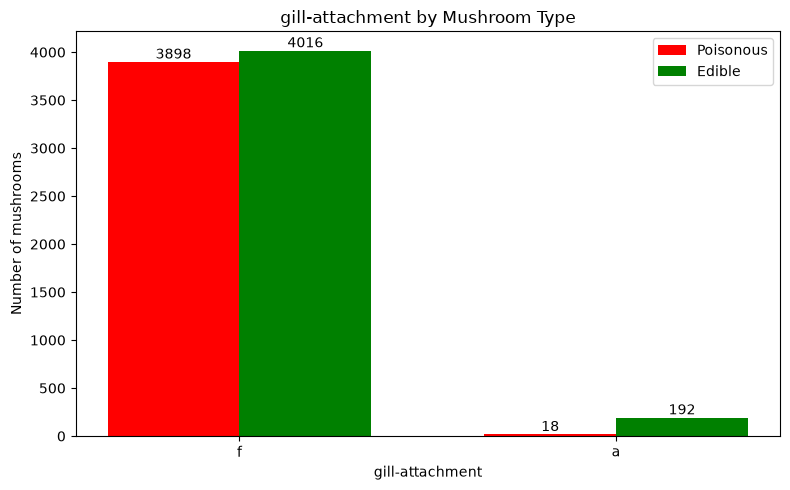

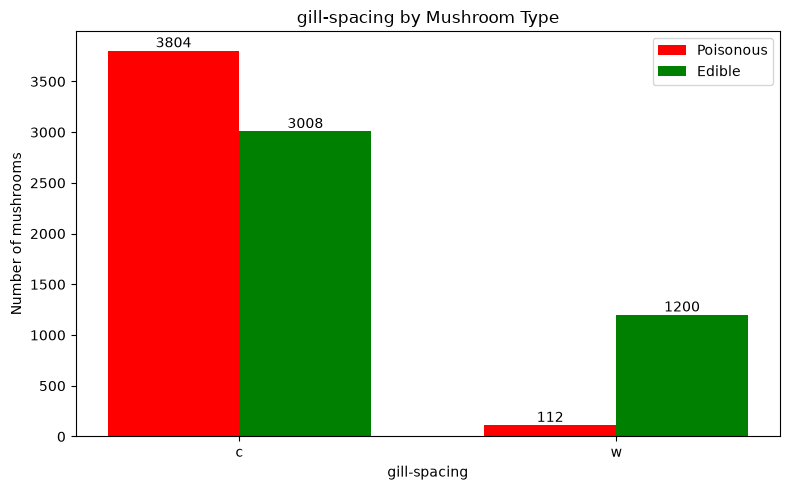

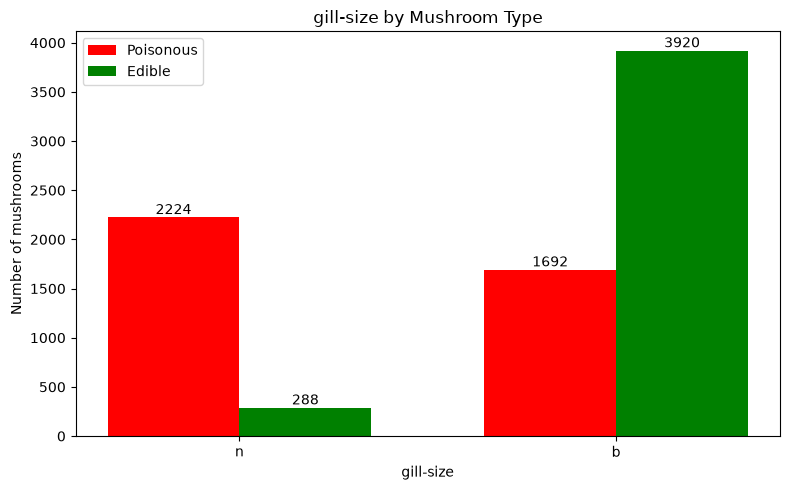

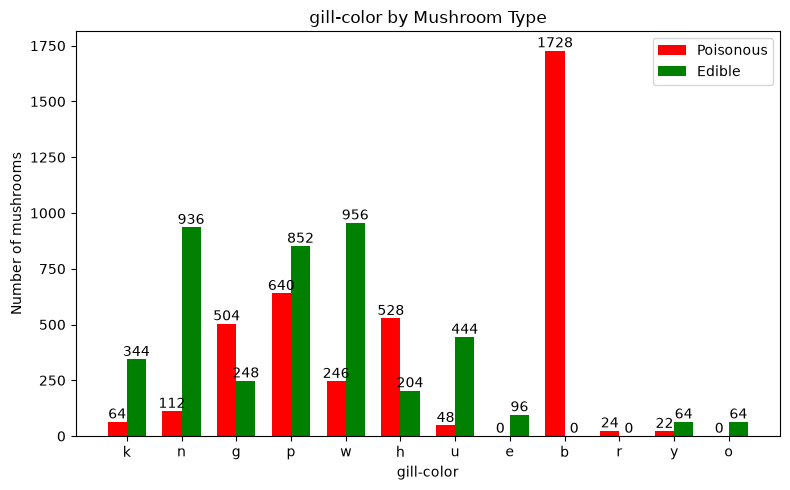

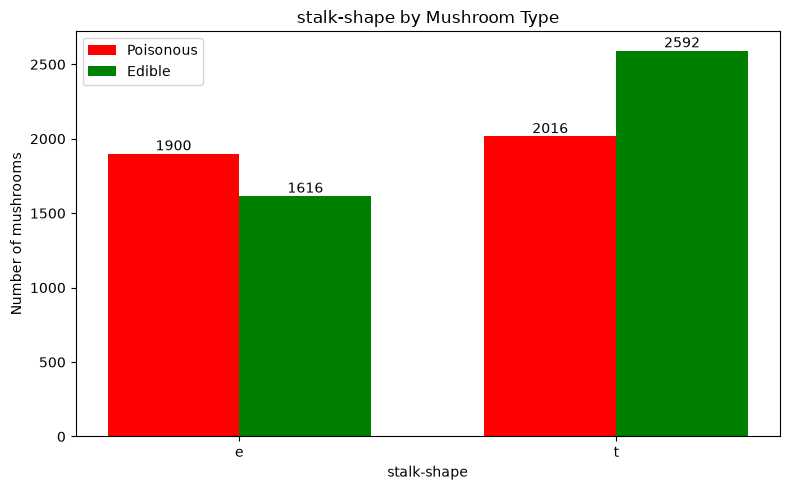

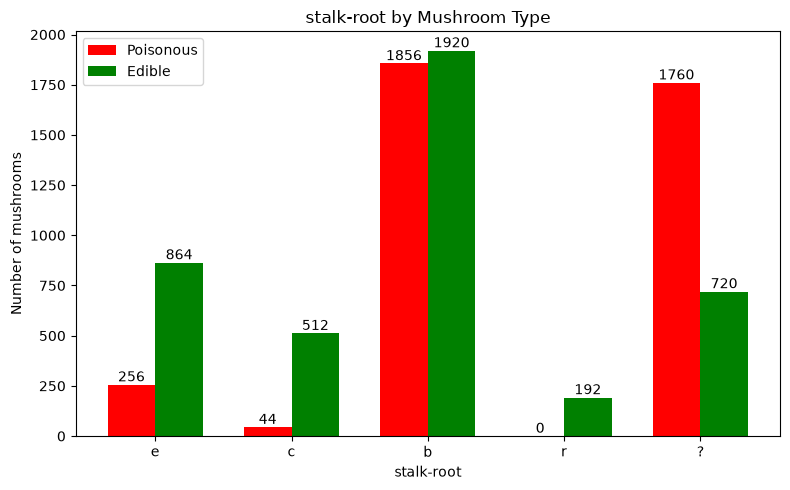

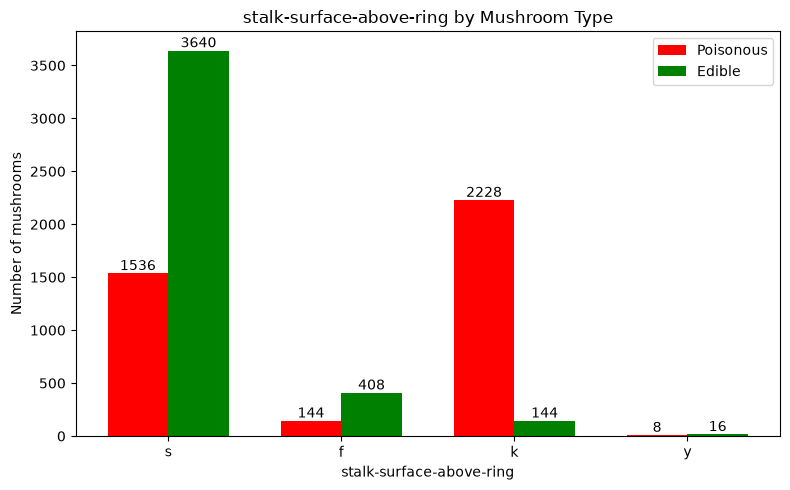

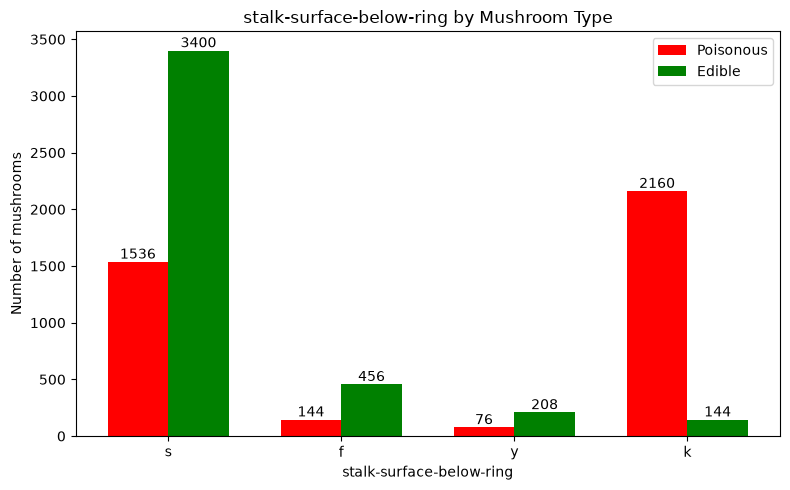

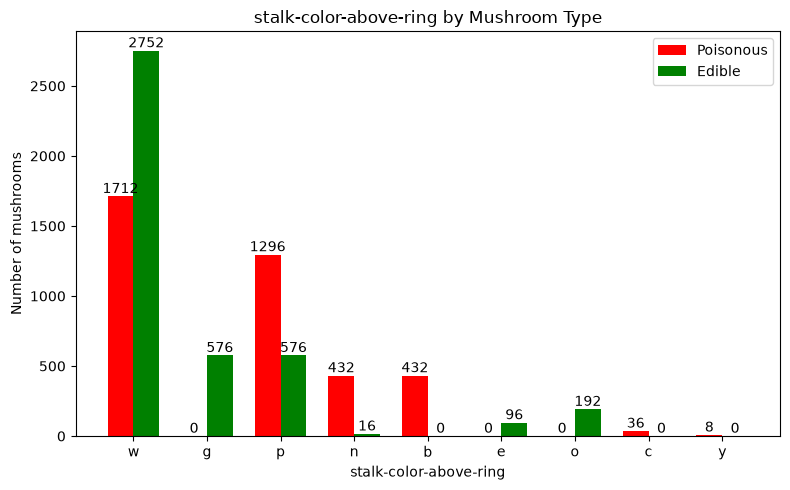

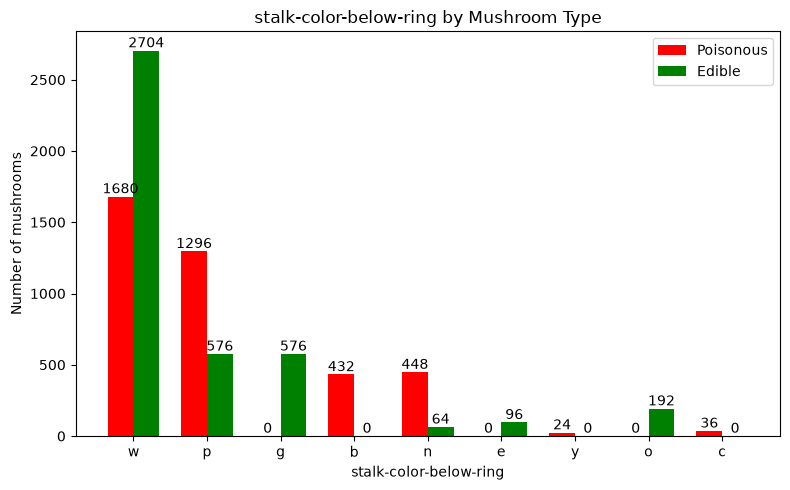

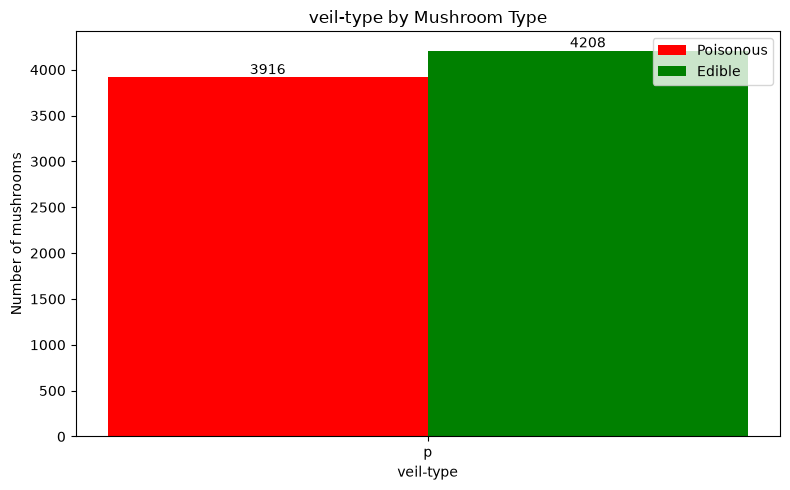

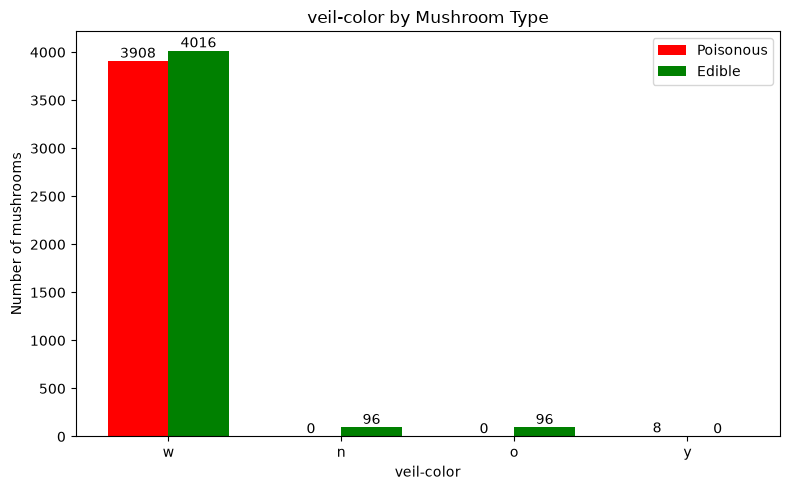

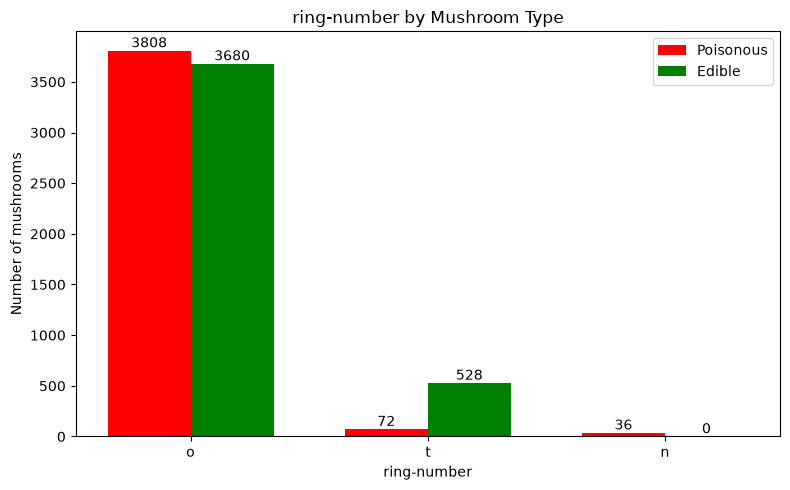

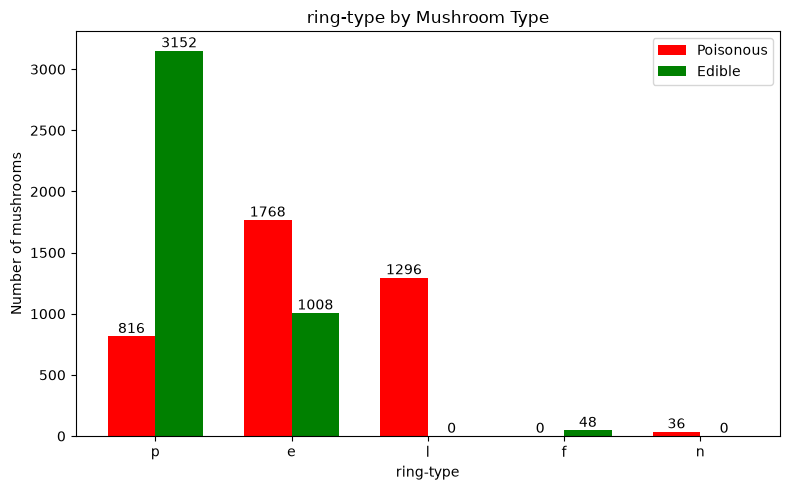

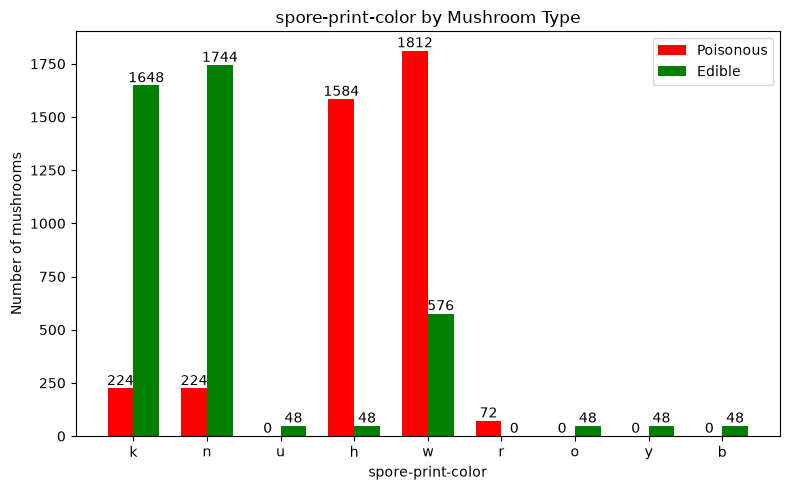

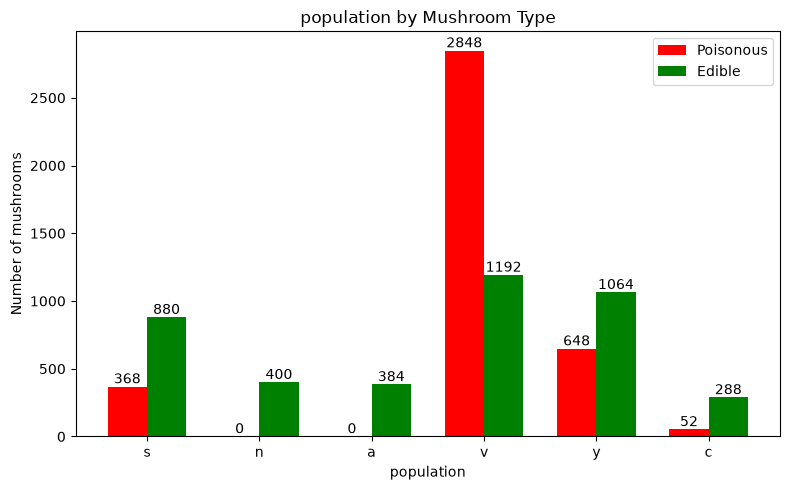

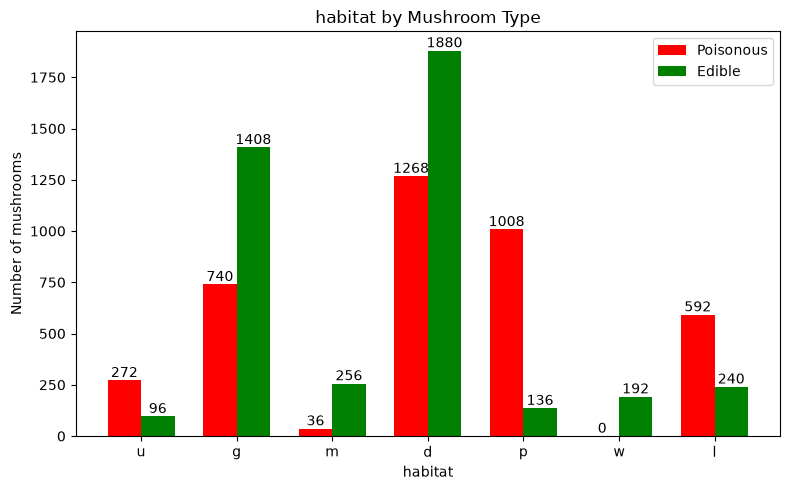

In [11]:

# drop poisonous column so can loop through features
features = df.drop("poisonous", axis=1)

for feature in features:
    # automatically find all possible values for this feature
    values = df[feature].dropna().unique()

    # Count each value in the poisonous and edible groups
    p_counts = [len(p_df[p_df[feature] == value]) for value in values]
    np_counts = [len(np_df[np_df[feature] == value]) for value in values]

    # Positions for the bars
    x = np.arange(len(values))
    width = 0.35

    # Plot grouped bars
    plt.figure(figsize=(8, 5))
    bars_p = plt.bar(x - width/2, p_counts, width, label='Poisonous', color='red')
    bars_np = plt.bar(x + width/2, np_counts, width, label='Edible', color='green')

    # displau values of bars above
    plt.bar_label(bars_p)
    plt.bar_label(bars_np)

    plt.xticks(x, values)
    plt.xlabel(feature)
    plt.ylabel('Number of mushrooms')
    plt.title(f'{feature} by Mushroom Type')
    plt.legend()
    plt.tight_layout()
    plt.show()


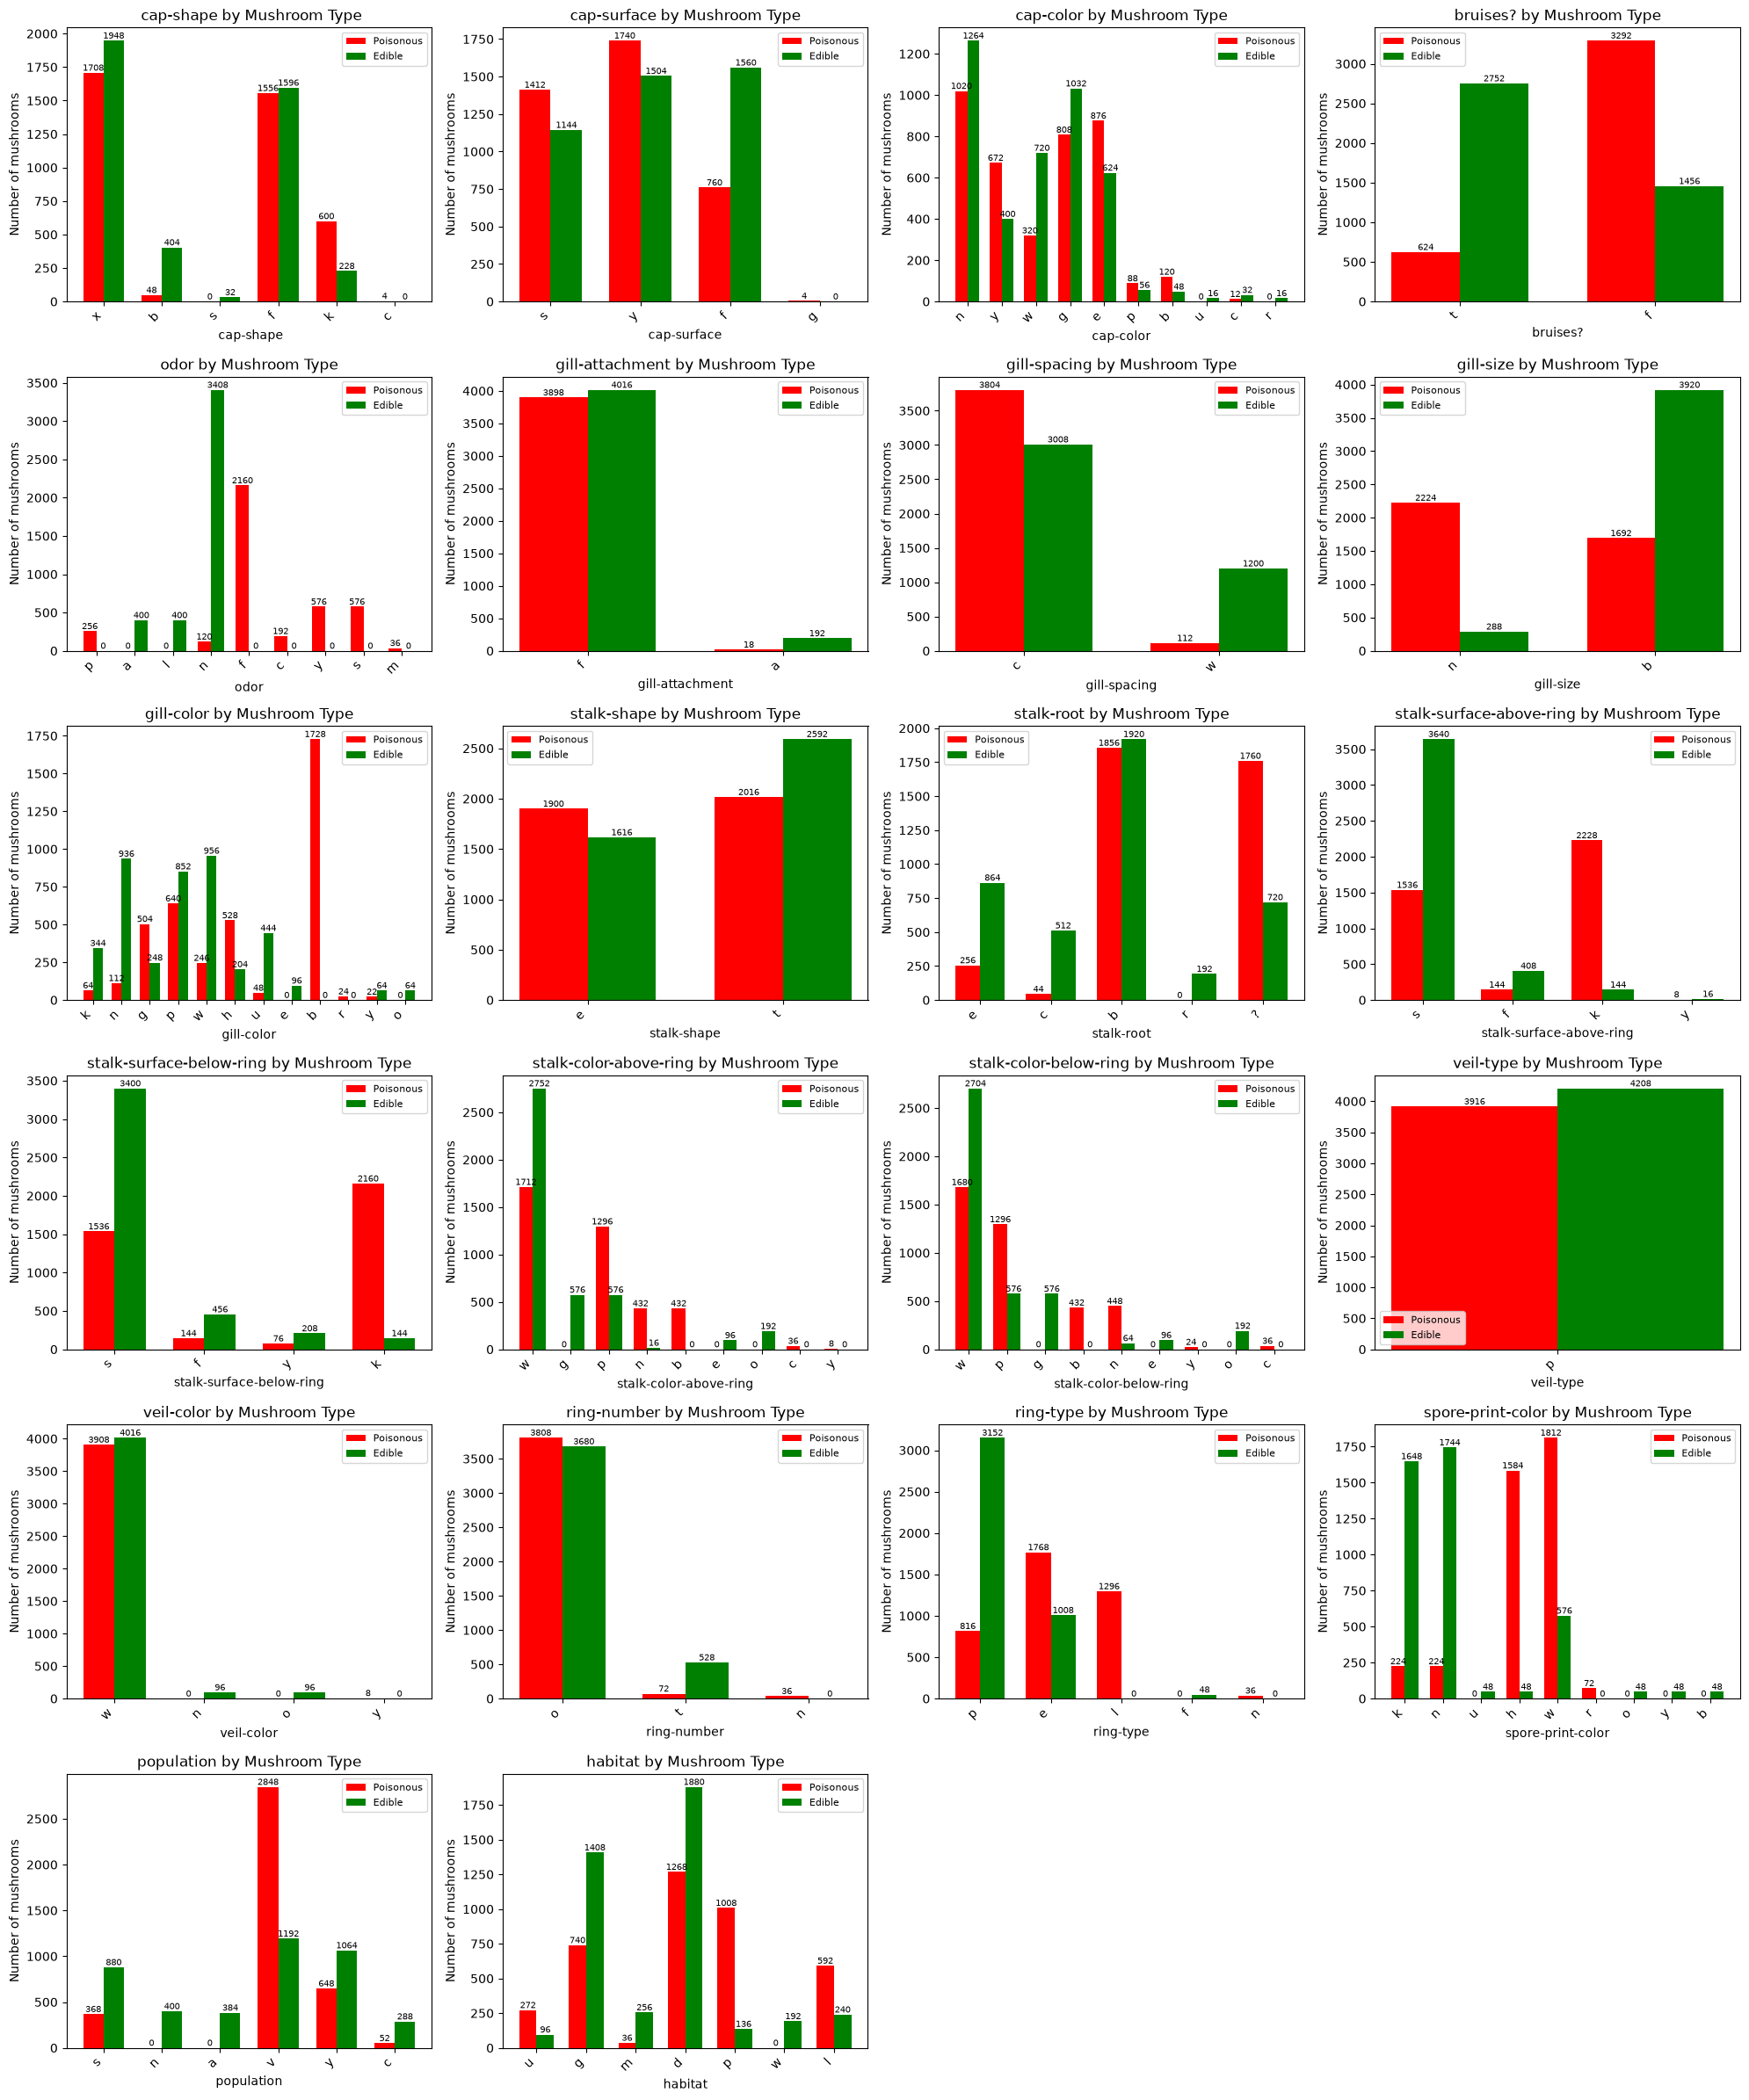

In [12]:
# Drop poisonous column so we can loop through features
features = df.drop("poisonous", axis=1)

# Calculate grid size for subplots
n_features = len(features.columns)
n_cols = 4
n_rows = int(np.ceil(n_features / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

# Flatten axes to make indexing easier
axes = np.array(axes).flatten()

for i, feature in enumerate(features.columns):
    ax = axes[i]

    # Automatically find all possible values for this feature
    values = df[feature].dropna().unique()

    # Count each value in the poisonous and edible groups
    p_counts = [
        len(p_df[p_df[feature] == value]) for value in values
    ]
    np_counts = [
        len(np_df[np_df[feature] == value]) for value in values
    ]

    # Positions for the bars
    x = np.arange(len(values))
    width = 0.35

    # Plot grouped bars on the current subplot
    bars_p = ax.bar(
        x - width/2, p_counts, width,
        label='Poisonous', color='red'
    )
    bars_np = ax.bar(
        x + width/2, np_counts, width,
        label='Edible', color='green'
    )

    # Display values above bars
    ax.bar_label(bars_p, fontsize=7)
    ax.bar_label(bars_np, fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(values, rotation=45, ha='right')
    ax.set_xlabel(feature)
    ax.set_ylabel('Number of mushrooms')
    ax.set_title(f'{feature} by Mushroom Type')
    ax.legend(fontsize=8)

# Remove unused subplots
for j in range(n_features, len(axes)):
    fig.delaxes(axes[j])

# Adjust spacing
plt.tight_layout()
plt.show()